# Mixture of Gaussians

Testing the mixture of gaussians clustering algorithm which is able to find clusters with hyper-ellipssoid shape.

entropy, kurtosis, crest factor.

test c-means and gaussian

test total_energy calculation, clean up code.

feature selection + numerical studies
(for k-means and c-means, which set of metrics works the best for each.)

1st paper is k-means
2nd paper compares k-means with c-means and gaussian.

then write up and focus on the second paper. dicuss different classification methods

how to test wavelet orders? better representation of transients vs computational cost and cluster separation.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
%matplotlib inline
sys.path.append("..")

import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [3]:
# Set sampling rate and noise std
sampling_rate = 50e6
std_noise = 0.01

# Set length of data to keep
sample_time = 20 / 2e6
data_len = int(sample_time * sampling_rate)

# Parameters for the wavelet transform
wavelet = "db20"
levels = 4
mode = "symmetric"

In [4]:
def generate_training_data_with_wavelet(wavelet, sampling_rate, levels, mode, std_noise, data_len=None):
    wpt_df = None
    for R_init in (i / 1e6 for i in range(4, 11, 2)):
        for frequency in [i * 1e5 for i in range(7, 10)]:
            for pac in [-i * 1e4 for i in range(1, 20, 2)]:
                data = train.get_data(R_init, frequency, pac, sampling_rate)
                data = (data - np.mean(data)) / np.std(data)
                data += np.random.normal(0, std_noise, size=len(data))

                l = len(data) if data_len is None else data_len
                data = data[:l]

                # Generate traning data using the wavelet transform
                training_data = train.generate_training_data(
                    data,
                    levels,
                    wavelet,
                    mode,
                    print_nodes_kept=False,
                    min_entropy=True,
                )

                if wpt_df is None:  # Init dataframe
                    wpt_df = training_data
                else:  # Add data to dataframe
                    wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

    # Add noise samples
    # print("adding noise")
    # add_noise = 0.1  # 1/10 of the dataset is noise
    # n = wpt_df.shape[0]
    # n_noise_samples = int(n * add_noise / (1 - add_noise))
    # for _ in range(n_noise_samples):
    #     noise = np.random.normal(0, std_noise, size=len(data))
    #     training_data = train.generate_training_data(noise, levels, wavelet, mode)
    #     wpt_df= pd.concat([wpt_df, training_data], ignore_index=True)

    return wpt_df

In [5]:
wpt_df = generate_training_data_with_wavelet(wavelet, sampling_rate, levels, mode, std_noise, data_len)

### Training

Train the mixture of gaussians on the generated data

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

# Get data
classifying_metrics = ["log energy", "level entropy", "kurtosis"]

def train_mixture_of_gaussians(wpt_df):
    # Get training data
    data_train = wpt_df[classifying_metrics]

    # Standardise data
    scaler = StandardScaler()
    data_train_normalised = scaler.fit_transform(data_train)

    # Parameters for mixture of gaussians
    no_clusters = 5

    # Mixture of gaussians clustering
    gm = GaussianMixture(no_clusters)
    labels = gm.fit_predict(data_train_normalised)

    # Cluster centres
    centers = scaler.inverse_transform(gm.means_)
    # print("centers:", centers)

    # # Hard cluster assignments
    # for i in range(no_clusters):
    #     print(f"label {i} count:", list(labels).count(i))

    return data_train, labels, data_train_normalised, centers, scaler

data_train, labels, data_train_normalised, centers, scaler = train_mixture_of_gaussians(wpt_df)

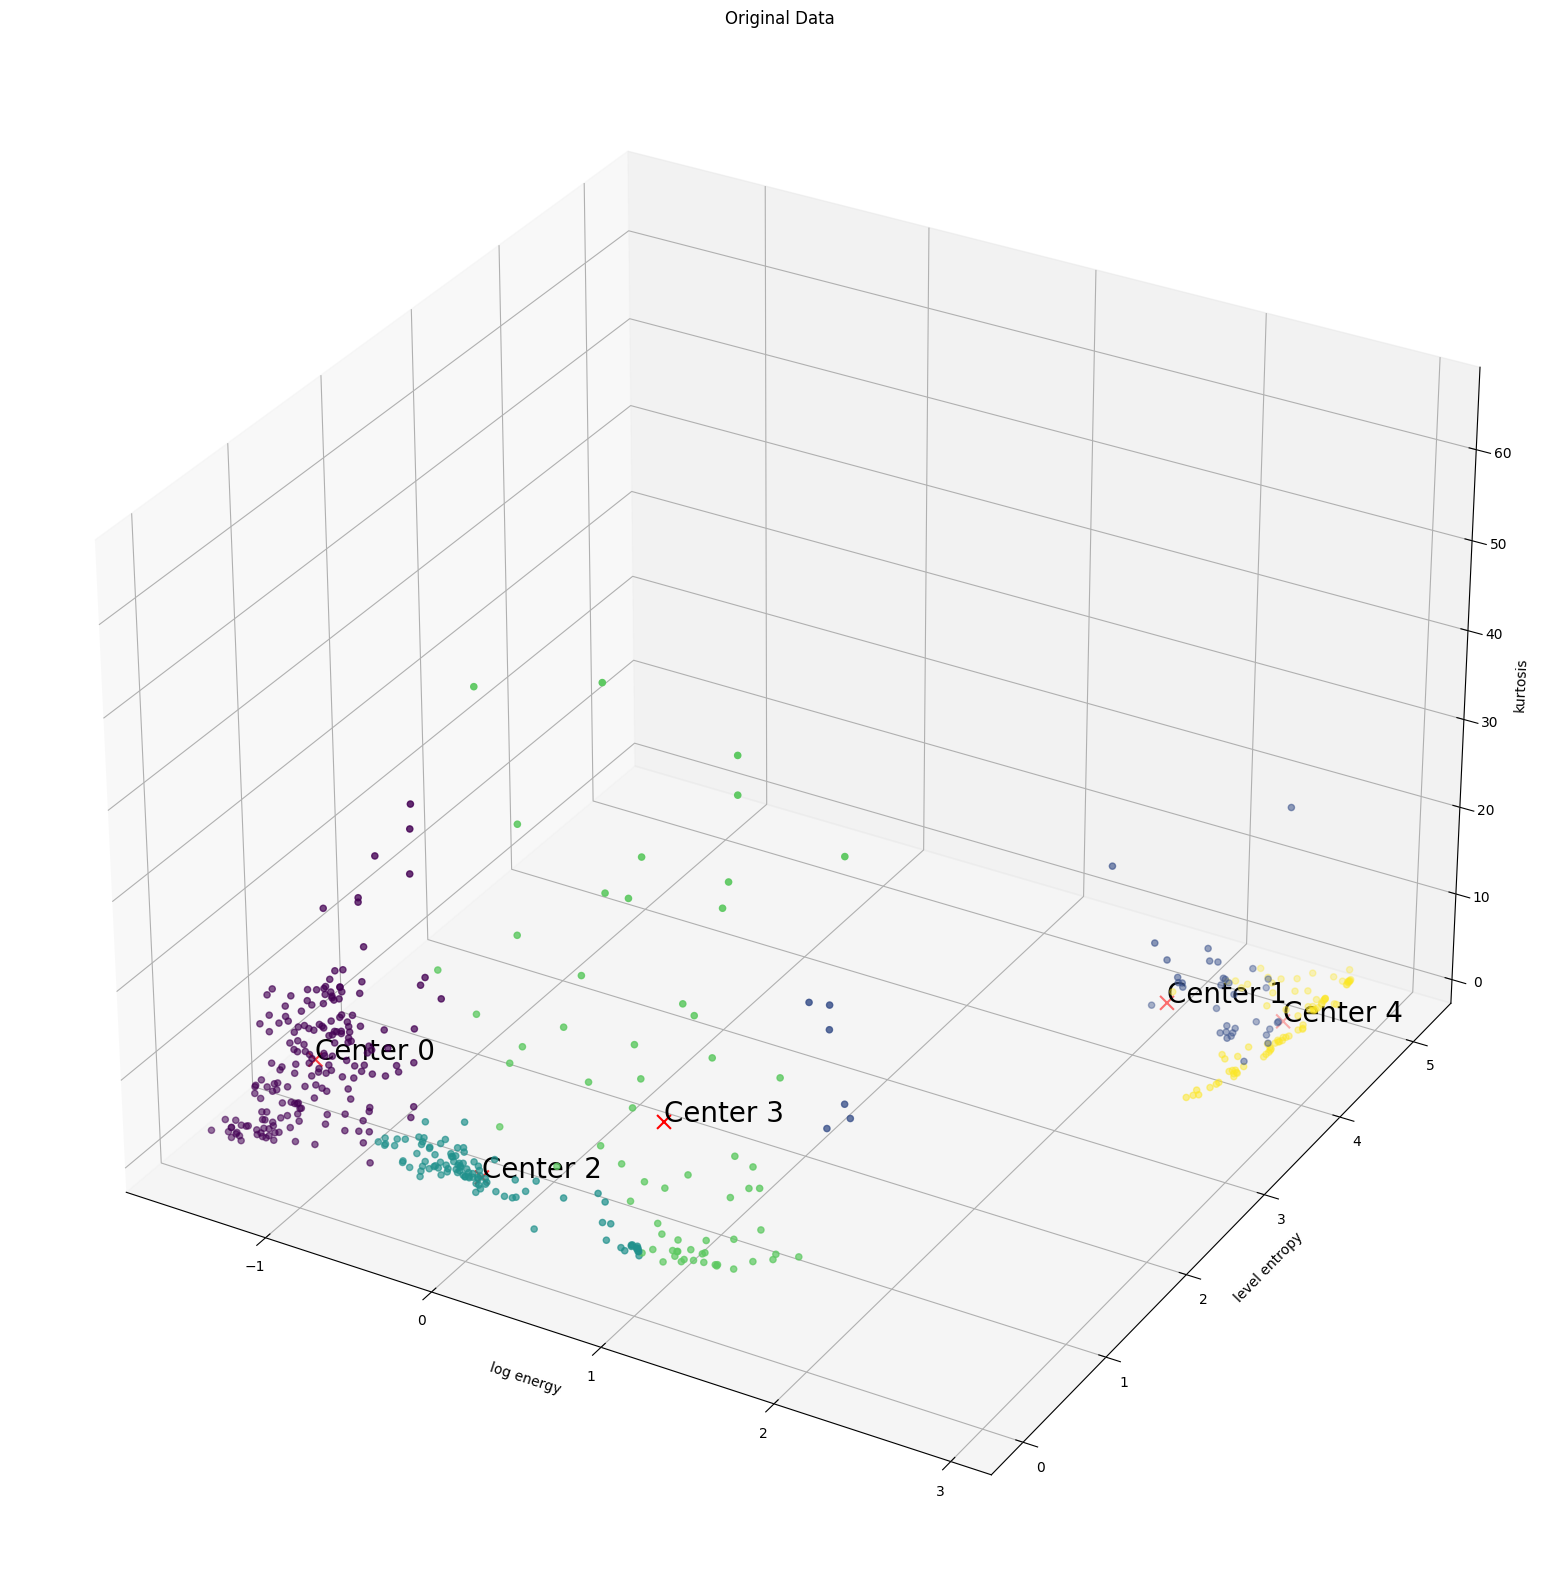

In [7]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()

### Numerical studies

In [20]:
wavelets = [f"db{i}" for i in range(4, 21)]

db4
db5
db6
db7
db8
db9
db10
db11
db12
db13
db14
db15
db16
db17
db18
db19
db20


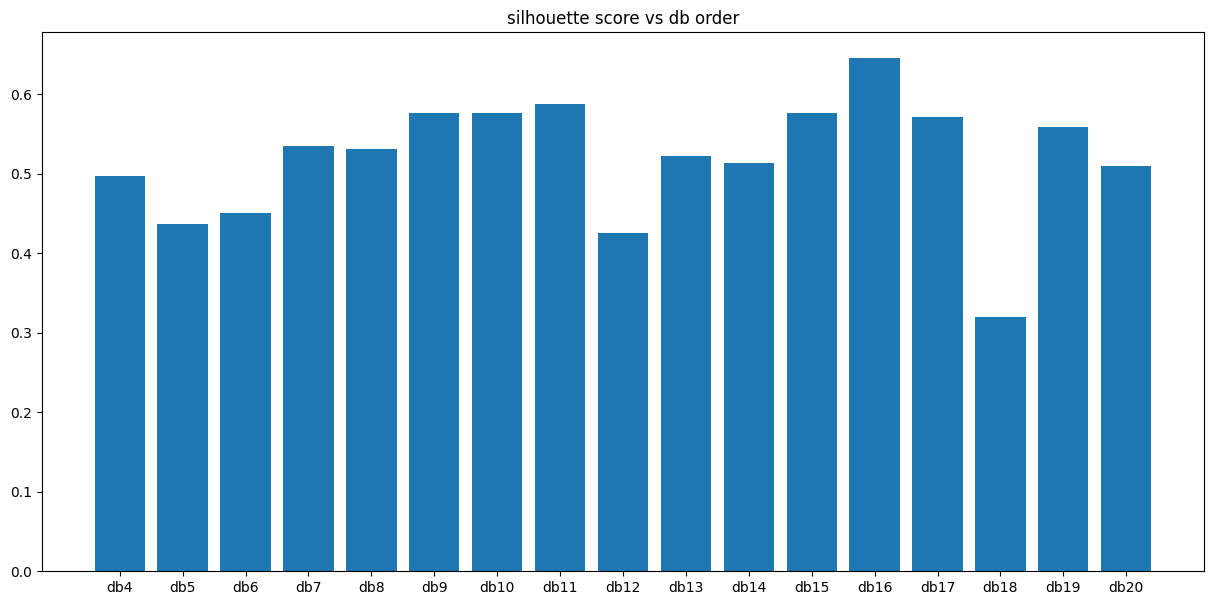

In [24]:
run = True
if run is True:
    from sklearn.metrics import silhouette_score
    scores = []

    for wavelet in wavelets:
        print(wavelet)
        wpt_df = generate_training_data_with_wavelet(wavelet, sampling_rate, levels, mode, std_noise, data_len)
        _, _labels, _data_train_normalised, *_   = train_mixture_of_gaussians(wpt_df)
        scores.append(silhouette_score(_data_train_normalised, _labels)) 
        
    fig, ax = plt.subplots()
    fig.set_size_inches(15, 7)
    plt.bar(wavelets, scores)
    plt.title("silhouette score vs db order")
    plt.show()

### Classifying new data points

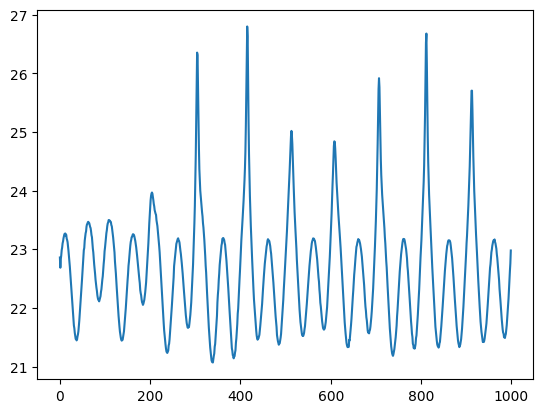

In [25]:
frequency = 10E5
pac = -2E5
R_init = 7e-6

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.get_data(R_init, frequency, pac, sampling_rate)
data = data / np.std(data)
data += np.random.normal(0, std_noise, len(data))

new_wpt_df, new_tr_ob = train.generate_training_data(
    data, 
    levels,
    wavelet, 
    mode,
    min_energy=min_energy,
    include_tr_ob=True,
    min_entropy=True
)

plt.plot(data)
plt.show()

In [9]:
# new_tr_ob.calc_frequencies(sampling_rate)
# plot.heisenberg(new_tr_ob)

In [13]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# New labels
new_labels = gm.predict(new_entry_normalized)

# Display the predicted results
print("Predicted hard cluster assignment:", labels)

Predicted hard cluster assignment: [4 0 4 0 4 3 1 3 2 1 3 1 3 1 3 1 3 1 3 1 3 4 0 1 0 1 3 1 3 3 1 2 1 2 1 2 1
 2 1 3 1 3 4 2 1 2 1 2 3 1 3 1 3 3 1 2 2 1 2 2 1 3 1 3 1 3 4 0 4 0 4 0 4 0
 4 0 4 0 4 0 1 3 1 3 1 2 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 1 0 4 3 4 3 4 0 4
 0 4 3 4 0 4 0 4 0 4 3 4 3 4 3 4 0 4 3 4 0 4 0 4 3 4 0 4 3 4 0 4 0 4 0 4 3
 4 0 4 0 4 0 4 3 4 2 4 3 4 0 4 3 4 3 4 3 4 0 4 0 4 2 4 2 4 3 4 3 4 3 4 3 4
 3 4 3 4 0 4 3 4 2 4 3 4 0 4 3 4 3 4 0 1 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0
 4 0 4 0 4 2 4 0 4 0 4 0 4 0 4 0 4 3 4 3 4 3 4 3]


Reconstructed nodes by group:


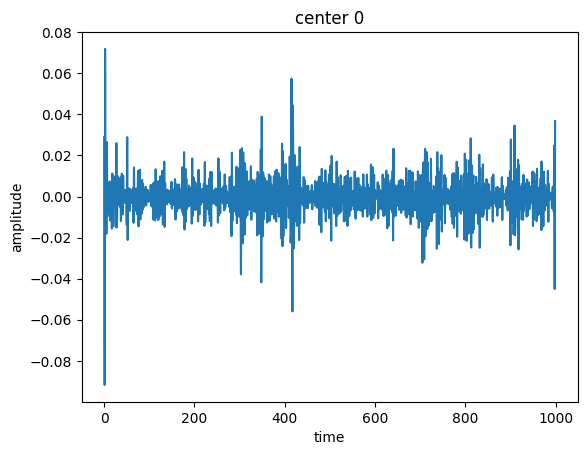

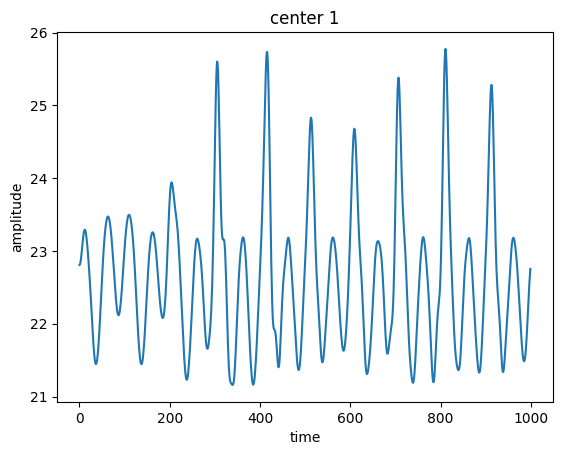

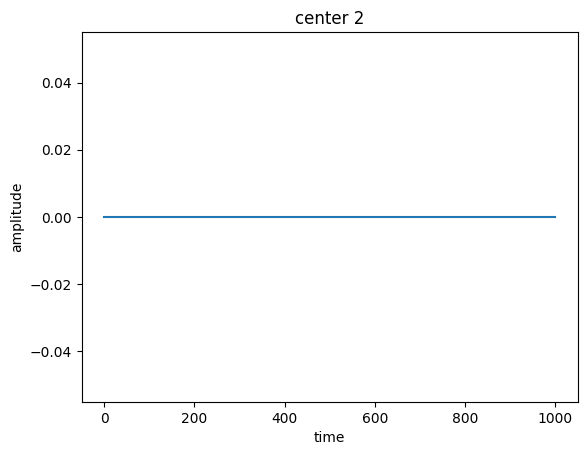

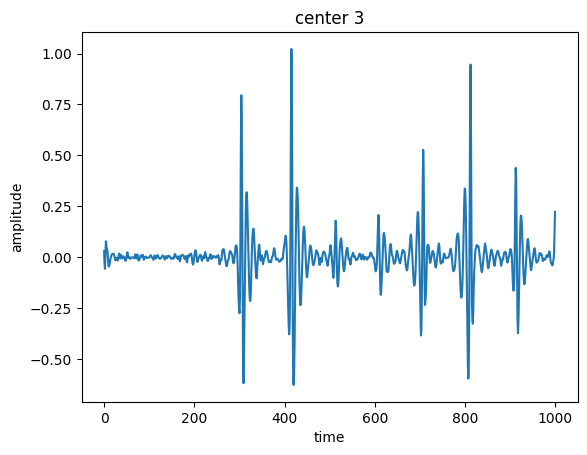

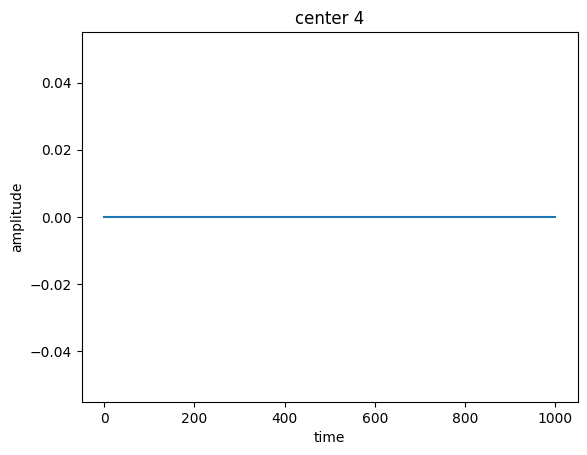

In [14]:
plot.plot_reconstructions_by_group(new_tr_ob, new_labels, no_clusters)